In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
files = list(Path("../data").rglob("*.xls*"))
print(f'Number of files: {len(files)}')

for file in files:
    print(file)

Number of files: 18
../data/2025/23MARCH25-1MAY25.xls
../data/2025/AUG 2025.xls
../data/2025/DEC 2025.xls
../data/2025/JAN 2025.xls
../data/2025/JULY 2025.xls
../data/2025/JuNE 2025.xls
../data/2025/MAY 2025.xls
../data/2025/NOV2025.xls
../data/2025/OCT 2025.xls
../data/2025/SEP 2025.xls
../data/2026/APR20-MAY42026.xls
../data/2026/August 2026.xls
../data/2026/FEB 2026.xls
../data/2026/JAN 2026.xls
../data/2026/JULY2026.xls
../data/2026/june 2026.xls
../data/2026/MARCH-APR 20.xls
../data/2026/MAY 2026.xls


In [3]:
df = pd.read_csv(files[0], sep='\t')
df.columns

Index(['Date(dd/mm/yy)', 'Time(HH:MM)', 'W Direction(Deg)', 'Temp(Deg C)',
       'R Humidity(%)', 'Solar(CCM)', 'B Pressure(mmHg)', 'Spd(Km/hr)',
       'Rain(mm)', 'Unnamed: 9'],
      dtype='str')

In [4]:
humidity_data = []

for file in files:
    df = pd.read_csv(file, sep="\t")

    df = df[[
        "Date(dd/mm/yy)",
        "Time(HH:MM)",
        "R Humidity(%)"
    ]]

    humidity_data.append(df)

humidity_data = pd.concat(humidity_data, ignore_index=True)

print(humidity_data.shape)
humidity_data.head()

(12692, 3)


,Date(dd/mm/yy),Time(HH:MM),R Humidity(%)
0,24/03/25,13:57,-System Restart-
1,24/03/25,14:00,16.0
2,24/03/25,14:27,-System Restart-
3,24/03/25,14:46,-System Restart-
4,24/03/25,15:23,-System Restart-


In [5]:
print(humidity_data["R Humidity(%)"].value_counts().head(10))
print(humidity_data["R Humidity(%)"].isna().sum())

R Humidity(%)
-System Restart-    254
96.5                234
96.4                186
96.6                123
96.1                102
96.0                 87
96                   85
-Transfer Error-     77
96.3                 60
73.2                 47
Name: count, dtype: int64
0


In [6]:
humidity_data["R Humidity(%)"] = pd.to_numeric(
    humidity_data["R Humidity(%)"],
    errors="coerce"
)

humidity_clean = humidity_data.dropna(
    subset=["R Humidity(%)"]
).copy()

print("Valid readings:", len(humidity_clean))
print(humidity_clean["R Humidity(%)"].describe())

Valid readings: 12361
count    12361.000000
mean        61.228598
std         24.230599
min          0.000000
25%         41.000000
50%         64.300000
75%         81.500000
max         96.600000
Name: R Humidity(%), dtype: float64


In [7]:
humidity_clean["Datetime"] = pd.to_datetime(
    humidity_clean["Date(dd/mm/yy)"].astype(str) + " " +
    humidity_clean["Time(HH:MM)"].astype(str),
    dayfirst=True,
    format="mixed",
    errors="coerce"
)

print("Invalid timestamps:", humidity_clean["Datetime"].isna().sum())

humidity_clean = humidity_clean.dropna(
    subset=["Datetime"]
).copy()

Invalid timestamps: 0


In [8]:
print("Minimum humidity:", humidity_clean["R Humidity(%)"].min())
print("Maximum humidity:", humidity_clean["R Humidity(%)"].max())

print(
    humidity_clean[
        (humidity_clean["R Humidity(%)"] < 0) |
        (humidity_clean["R Humidity(%)"] > 100)
    ]
)

Minimum humidity: 0.0
Maximum humidity: 96.6
Empty DataFrame
Columns: [Date(dd/mm/yy), Time(HH:MM), R Humidity(%), Datetime]
Index: []


In [9]:
duplicate_check = humidity_clean.groupby("Datetime")["R Humidity(%)"].agg(
    ["count", "nunique"]
)

duplicate_check = duplicate_check[duplicate_check["count"] > 1]

print("Duplicate timestamps:", len(duplicate_check))
print(
    "Timestamps with conflicting humidity readings:",
    (duplicate_check["nunique"] > 1).sum()
)

Duplicate timestamps: 89
Timestamps with conflicting humidity readings: 0


In [10]:
humidity_clean = humidity_clean.drop_duplicates(
    subset=["Datetime", "R Humidity(%)"]
).copy()

print("Final observations:", len(humidity_clean))

Final observations: 12272


In [11]:
humidity_clean["Month"] = humidity_clean["Datetime"].dt.to_period("M")

monthly_humidity = humidity_clean.groupby("Month").agg(
    Average_Humidity=("R Humidity(%)", "mean"),
    Maximum_Humidity=("R Humidity(%)", "max"),
    Minimum_Humidity=("R Humidity(%)", "min"),
    Observations=("R Humidity(%)", "count")
).reset_index()

print(monthly_humidity.to_string(index=False))

  Month  Average_Humidity  Maximum_Humidity  Minimum_Humidity  Observations
 110-10          0.000000               0.0               0.0             1
2024-12         61.984835              96.2              18.0           699
2025-01         52.167273              79.5              18.1            55
2025-03         23.162286              46.1              10.0           175
2025-04         32.444444              91.4               7.2           711
2025-05         50.833559              95.5              19.0           739
2025-06         58.786294              96.6              17.2           715
2025-07         83.651144              96.6              45.5           743
2025-08         80.256604              96.6              40.5           742
2025-09         82.372245              96.6              41.0           717
2025-10         73.334641              96.5              37.3           739
2025-11         65.978962              96.5              22.0           713
2025-12     

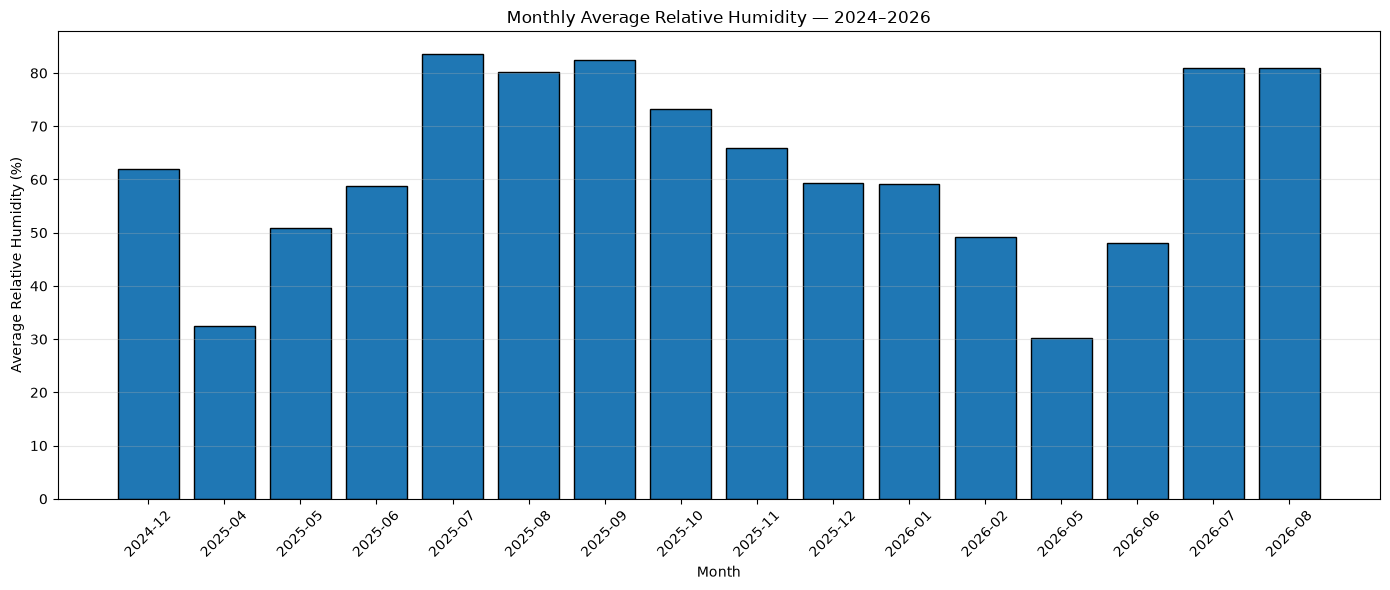

In [12]:
humidity_reliable = monthly_humidity[
    monthly_humidity["Observations"] >= 600
].copy()

humidity_reliable["Month"] = humidity_reliable["Month"].astype(str)

plt.figure(figsize=(14, 6))

plt.bar(
    humidity_reliable["Month"],
    humidity_reliable["Average_Humidity"],
    edgecolor="black"
)

plt.xlabel("Month")
plt.ylabel("Average Relative Humidity (%)")
plt.title("Monthly Average Relative Humidity — 2024–2026")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

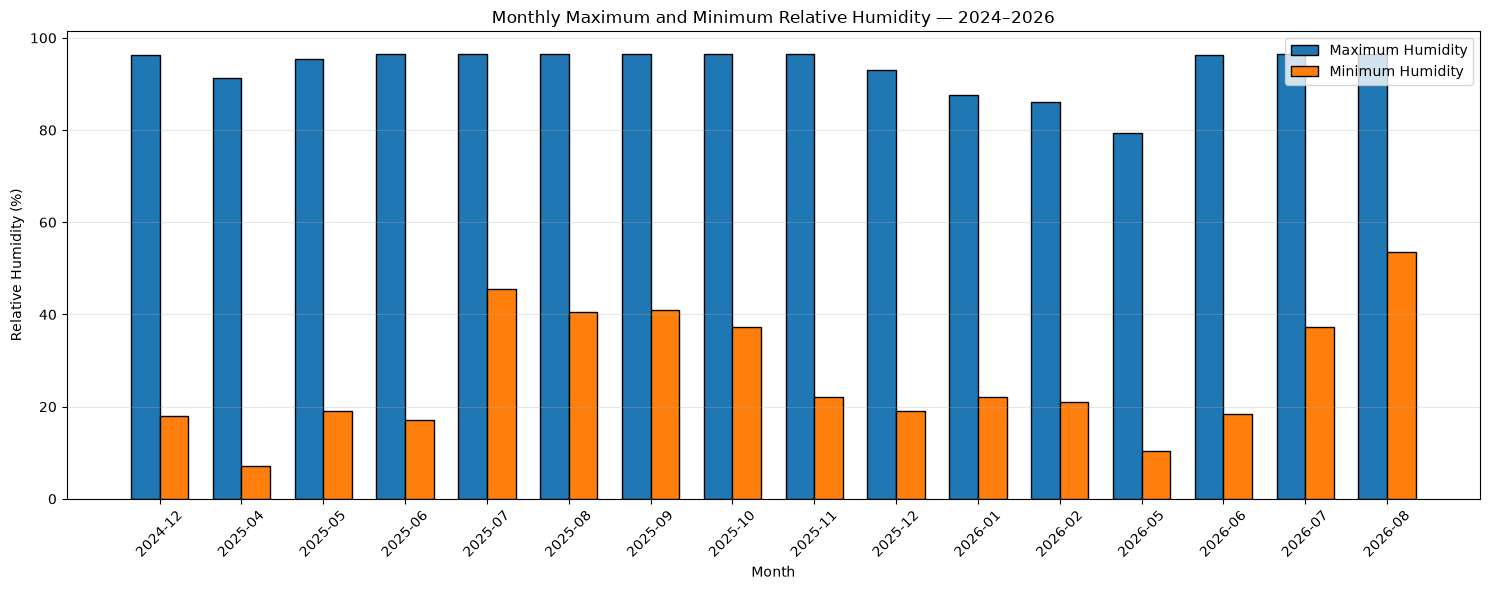

In [13]:
x = np.arange(len(humidity_reliable))
width = 0.35

plt.figure(figsize=(15, 6))

plt.bar(
    x - width/2,
    humidity_reliable["Maximum_Humidity"],
    width,
    label="Maximum Humidity",
    edgecolor="black"
)

plt.bar(
    x + width/2,
    humidity_reliable["Minimum_Humidity"],
    width,
    label="Minimum Humidity",
    edgecolor="black"
)

plt.xlabel("Month")
plt.ylabel("Relative Humidity (%)")
plt.title("Monthly Maximum and Minimum Relative Humidity — 2024–2026")

plt.xticks(x, humidity_reliable["Month"], rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
humidity_clean = humidity_clean[
    humidity_clean["Datetime"].dt.year.between(2024, 2026)
].copy()

humidity_clean["Month"] = humidity_clean["Datetime"].dt.to_period("M")

monthly_humidity = humidity_clean.groupby("Month").agg(
    Average_Humidity=("R Humidity(%)", "mean"),
    Maximum_Humidity=("R Humidity(%)", "max"),
    Minimum_Humidity=("R Humidity(%)", "min"),
    Observations=("R Humidity(%)", "count")
).reset_index()

print(monthly_humidity.to_string(index=False))

  Month  Average_Humidity  Maximum_Humidity  Minimum_Humidity  Observations
2024-12         61.984835              96.2              18.0           699
2025-01         52.167273              79.5              18.1            55
2025-03         23.162286              46.1              10.0           175
2025-04         32.444444              91.4               7.2           711
2025-05         50.833559              95.5              19.0           739
2025-06         58.786294              96.6              17.2           715
2025-07         83.651144              96.6              45.5           743
2025-08         80.256604              96.6              40.5           742
2025-09         82.372245              96.6              41.0           717
2025-10         73.334641              96.5              37.3           739
2025-11         65.978962              96.5              22.0           713
2025-12         59.340595              93.0              19.0           739
2026-01     